# 03 — Análise fatorial

Spec 002, perguntas Q2.1 a Q2.4. A **análise fatorial (AF)** supõe que cada item é explicado por fatores comuns
mais um erro próprio: $x = \Lambda f + \varepsilon$, com $\mathrm{Cov}(x) = \Lambda\Phi\Lambda^\top + \Psi$.
Diferente da PCA (que resume a variância **total**), a AF modela só a variância **comum** — a parte que os
itens compartilham. Os números deste notebook são recalculados aqui e conferidos com `resultados/002/tabelas/`.

In [1]:
import sys, pathlib
raiz = pathlib.Path.cwd()
while not (raiz / "analise").is_dir():
    raiz = raiz.parent
sys.path.insert(0, str(raiz))
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
from IPython.display import Image, display
from analise.comum import caminhos, multivariada as mv
from analise.comum.estatistica import le_csv
pd.set_option("display.precision", 3); pd.set_option("display.width", 160)
TAB = caminhos.RESULTADOS / "002" / "tabelas"; FIG = caminhos.RESULTADOS / "002" / "figuras"

pns = pd.read_parquet(caminhos.processado("pns2019")); nh = pd.read_parquet(caminhos.processado("nhanes0506"))
phq = [f"phq{i}" for i in range(1, 10)]
from analise.harmonizacao.recodes import PHQ_ROTULOS
Xb = pns[phq].dropna().to_numpy(float); Xu = nh[phq].dropna().to_numpy(float)
Rb, Ru = np.corrcoef(Xb, rowvar=False), np.corrcoef(Xu, rowvar=False)
print("PHQ-9: PNS n =", len(Xb), " NHANES n =", len(Xu))

PHQ-9: PNS n = 88531  NHANES n = 4799


## 1. Os dados servem para AF? KMO, MSA, Bartlett e α

- **KMO** compara as correlações com as correlações **parciais** (pela inversa de $R$):
  $\mathrm{KMO} = \sum r_{ij}^2 / (\sum r_{ij}^2 + \sum q_{ij}^2)$. Perto de 1 = os itens compartilham variância;
  regra prática KMO ≥ 0,60 (*a verificar*). O **MSA** é o mesmo índice item a item.
- **Bartlett**: testa $H_0$: $R = I$ (itens não correlacionados).
  $\chi^2 = -(n-1-(2p+5)/6)\ln|R|$, gl $= p(p-1)/2$.
- **α de Cronbach**: consistência interna, $\alpha = \frac{k}{k-1}(1 - \sum s_j^2 / s_T^2)$.

In [2]:
for nome, X, R in (("PNS 2019", Xb, Rb), ("NHANES 2005-06", Xu, Ru)):
    k, msa = mv.kmo(R); chi2, gl, pv = mv.bartlett(R, len(X))
    print(f"{nome}: KMO = {k:.3f}; MSA mín = {msa.min():.3f}; Bartlett χ² = {chi2:,.1f}, gl = {gl}, p = {pv:.2e}; α = {mv.alfa_cronbach(X):.3f}")

PNS 2019: KMO = 0.903; MSA mín = 0.859; Bartlett χ² = 291,781.2, gl = 36, p = 0.00e+00; α = 0.856
NHANES 2005-06: KMO = 0.892; MSA mín = 0.867; Bartlett χ² = 11,949.5, gl = 36, p = 0.00e+00; α = 0.821


Com n de milhares, o Bartlett rejeita $H_0$ sempre (p arredondado para 0): ele só confirma que há correlação a
modelar. O tamanho do efeito está no KMO e no α.

## 2. Extração por máxima verossimilhança (ML) e por eixos principais

- **ML**: escolhe as unicidades $\Psi$ que maximizam a verossimilhança normal; minimiza
  $-\sum_{j>k}(\ln\lambda_j - \lambda_j) - k + p$ sobre os autovalores de $\Psi^{-1/2}R\Psi^{-1/2}$.
- **Eixos principais**: troca a diagonal de $R$ pelas comunalidades $h^2$ e repete a decomposição até convergir.

**Comunalidade** $h_j^2 = \sum_k \lambda_{jk}^2$ = parte da variância do item explicada pelos fatores;
**unicidade** $= 1 - h_j^2$.

In [3]:
mlb, mlu = mv.af_ml(Rb, 1), mv.af_ml(Ru, 1)
pab = mv.af_eixos_principais(Rb, 1)
pd.DataFrame({"PNS ML": mlb["cargas"][:, 0], "PNS eixos": pab["cargas"][:, 0], "PNS h²": mlb["comunalidades"],
              "NHANES ML": mlu["cargas"][:, 0], "NHANES h²": mlu["comunalidades"]}, index=PHQ_ROTULOS).round(3)

,PNS ML,PNS eixos,PNS h²,NHANES ML,NHANES h²
interesse,0.754,0.753,0.568,0.651,0.423
deprimido,0.773,0.773,0.597,0.748,0.559
sono,0.543,0.545,0.295,0.549,0.301
cansaço,0.675,0.677,0.456,0.594,0.353
apetite,0.571,0.575,0.327,0.552,0.304
fracasso,0.691,0.686,0.478,0.691,0.478
concentração,0.687,0.686,0.472,0.596,0.355
psicomotor,0.627,0.631,0.393,0.513,0.263
autolesão,0.464,0.459,0.215,0.494,0.244


## 3. Congruência de Tucker: a estrutura é a mesma no Brasil e nos EUA?

$\varphi = \sum a_i b_i / \sqrt{\sum a_i^2 \sum b_i^2}$. Lorenzo-Seva e ten Berge (2006,
doi:10.1027/1614-2241.2.2.57, limites conferidos no resumo registrado no Crossref): **0,85–0,94 = similaridade
razoável; acima de 0,95 = fatores considerados iguais**. Cuidado: com todas as cargas positivas, φ tende a sair
alto; por isso a tabela também traz a maior diferença absoluta entre cargas.

In [4]:
print("PHQ-9, 1 fator ML: Tucker φ =", round(mv.tucker(mlb["cargas"][:, 0], mlu["cargas"][:, 0]), 4))
le_csv(TAB / "tucker.csv")[["hipotese", "instrumento", "solucao", "fator", "phi", "classificacao", "dif_max_carga"]]

PHQ-9, 1 fator ML: Tucker φ = 0.997


,hipotese,instrumento,solucao,fator,phi,classificacao,dif_max_carga
0,H2.2,3 sintomas de insônia,AF ML 1 fator (Pearson),F1,0.998,"equivalente (≥ 0,95)",0.078
1,H2.2,3 sintomas de insônia,PCA 1º componente,F1,1.000,"equivalente (≥ 0,95)",0.041
2,H2.2,3 sintomas de insônia,AF ML 1 fator (policórica),F1,0.999,"equivalente (≥ 0,95)",0.062
3,H2.2,3 sintomas de insônia,AF ML 1 fator (ponderada),F1,0.996,"equivalente (≥ 0,95)",0.095
4,H2.3,PHQ-9,AF ML 1 fator (Pearson),F1,0.997,"equivalente (≥ 0,95)",0.114
5,H2.3,PHQ-9,PCA 1º componente,F1,0.998,"equivalente (≥ 0,95)",0.097
6,H2.3,PHQ-9,AF ML 1 fator (policórica),F1,0.999,"equivalente (≥ 0,95)",0.076
7,H2.3,PHQ-9,AF ML 1 fator (ponderada),F1,0.998,"equivalente (≥ 0,95)",0.119
8,H2.3 (exploratória),PHQ-9,AF ML 2 fatores oblimin (oblimin (exploratória...,pns2019 F1 × nhanes0506 F2,0.852,"similar (0,85–0,94)",0.499
9,H2.3 (exploratória),PHQ-9,AF ML 2 fatores oblimin (oblimin (exploratória...,pns2019 F2 × nhanes0506 F1,0.859,"similar (0,85–0,94)",0.409


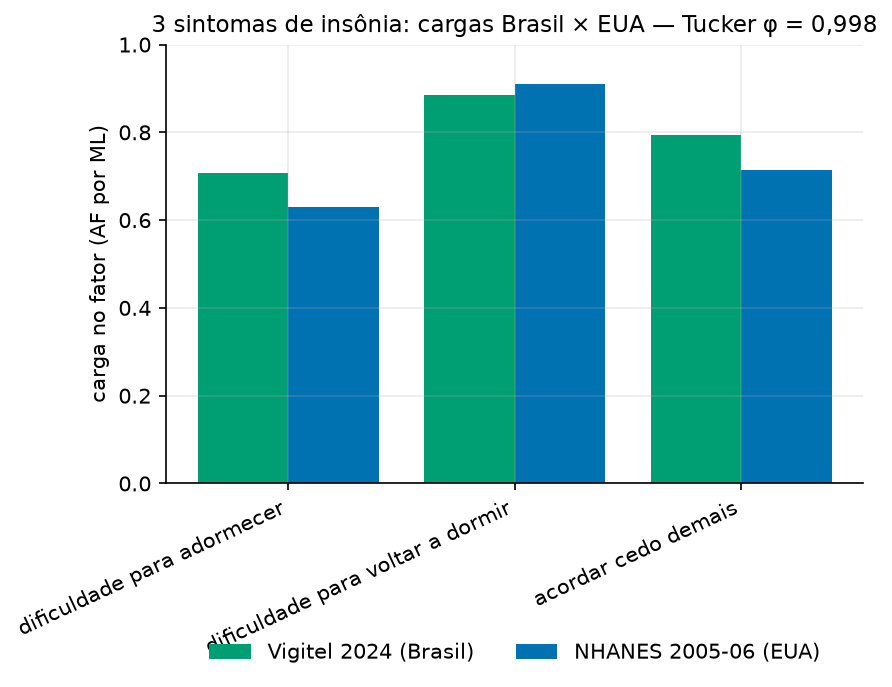

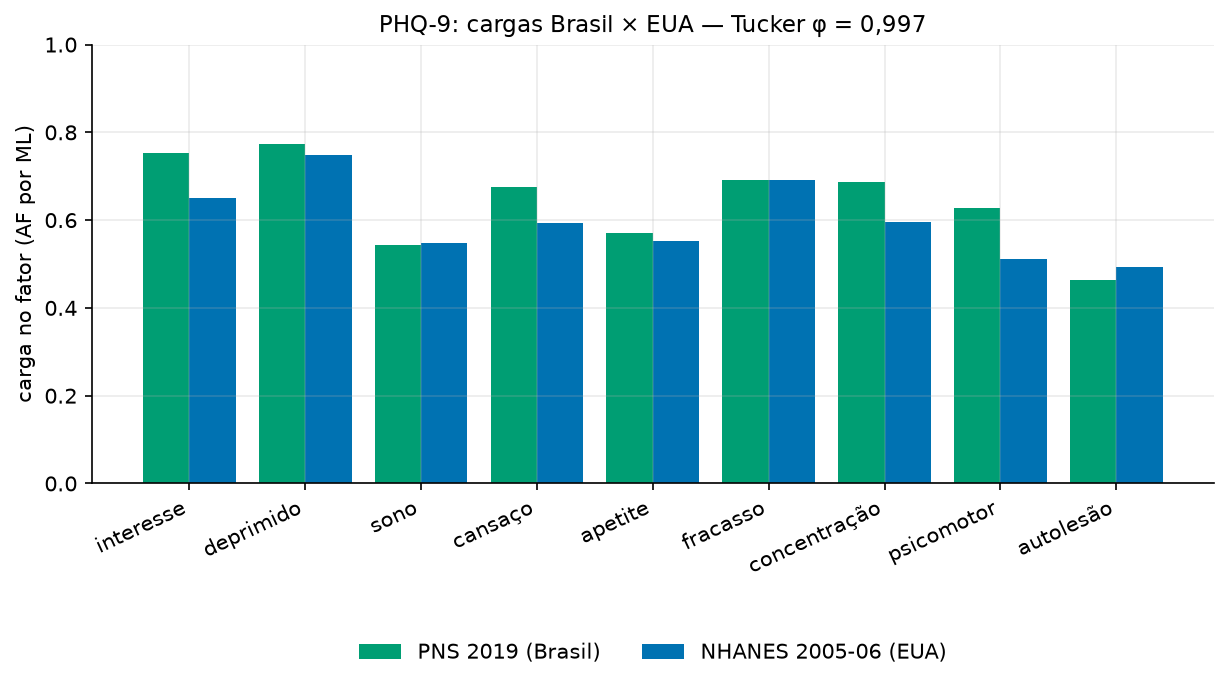

In [5]:
display(Image(filename=str(FIG / "cargas_insonia_br_eua.png"))); display(Image(filename=str(FIG / "cargas_phq9_br_eua.png")))

## 4. Onde carrega o item de sono do PHQ-9? (H2.4)

Com 1 fator (a solução retida pela análise paralela nos dois países), o item de sono carrega no único fator.
Como a literatura costuma separar no PHQ-9 um fator **somático** e um **afetivo**, rodamos também uma solução
**exploratória** de 2 fatores com rotação **oblimin** (oblíqua: os fatores podem se correlacionar; Φ é a
correlação entre eles).

In [6]:
for nome, R in (("PNS", Rb), ("NHANES", Ru)):
    L2 = mv.af_ml(R, 2)["cargas"]; P, Phi, _ = mv.oblimin(L2)
    df = pd.DataFrame(P, index=PHQ_ROTULOS, columns=["F1", "F2"]).round(2)
    print(f"--- {nome}: Φ(F1,F2) = {Phi[0,1]:.3f}"); display(df)

--- PNS: Φ(F1,F2) = 0.692


,F1,F2
interesse,0.74,0.05
deprimido,0.32,0.54
sono,0.60,-0.04
cansaço,0.83,-0.13
apetite,0.50,0.10
fracasso,-0.01,0.86
concentração,0.63,0.08
psicomotor,0.53,0.12
autolesão,0.00,0.54


--- NHANES: Φ(F1,F2) = 0.656


,F1,F2
interesse,0.46,0.24
deprimido,0.67,0.13
sono,0.09,0.57
cansaço,-0.04,0.80
apetite,0.25,0.37
fracasso,0.71,0.02
concentração,0.49,0.15
psicomotor,0.49,0.05
autolesão,0.63,-0.13


Nos dois países o item de sono fica no mesmo fator que **cansaço** (o fator somático), não no do humor
deprimido. A ordem F1/F2 muda de uma base para outra, mas o agrupamento é o mesmo.

## 5. Conjuntos com 2 fatores: varimax × oblimin

Para SAS-SV (Xuzhou), procrastinação do sono (Turquia) e BPS (Japão) a análise paralela retém 2 fatores.
**Varimax** força fatores não correlacionados (ortogonal); **oblimin** permite correlação.

,conjunto,metodo,k,fator_a,fator_b,phi
0,phq9_pns,ml (exploratória),2,F1,F2,0.692
1,phq9_nhanes,ml (exploratória),2,F1,F2,0.656
2,sassv_xuzhou,ml,2,F1,F2,0.607
3,sassv_xuzhou,eixos principais,2,F1,F2,0.612
4,procrastinacao_turquia,ml,2,F1,F2,0.383
5,procrastinacao_turquia,eixos principais,2,F1,F2,0.377
6,bps_japao,ml,2,F1,F2,0.188
7,bps_japao,eixos principais,2,F1,F2,0.189


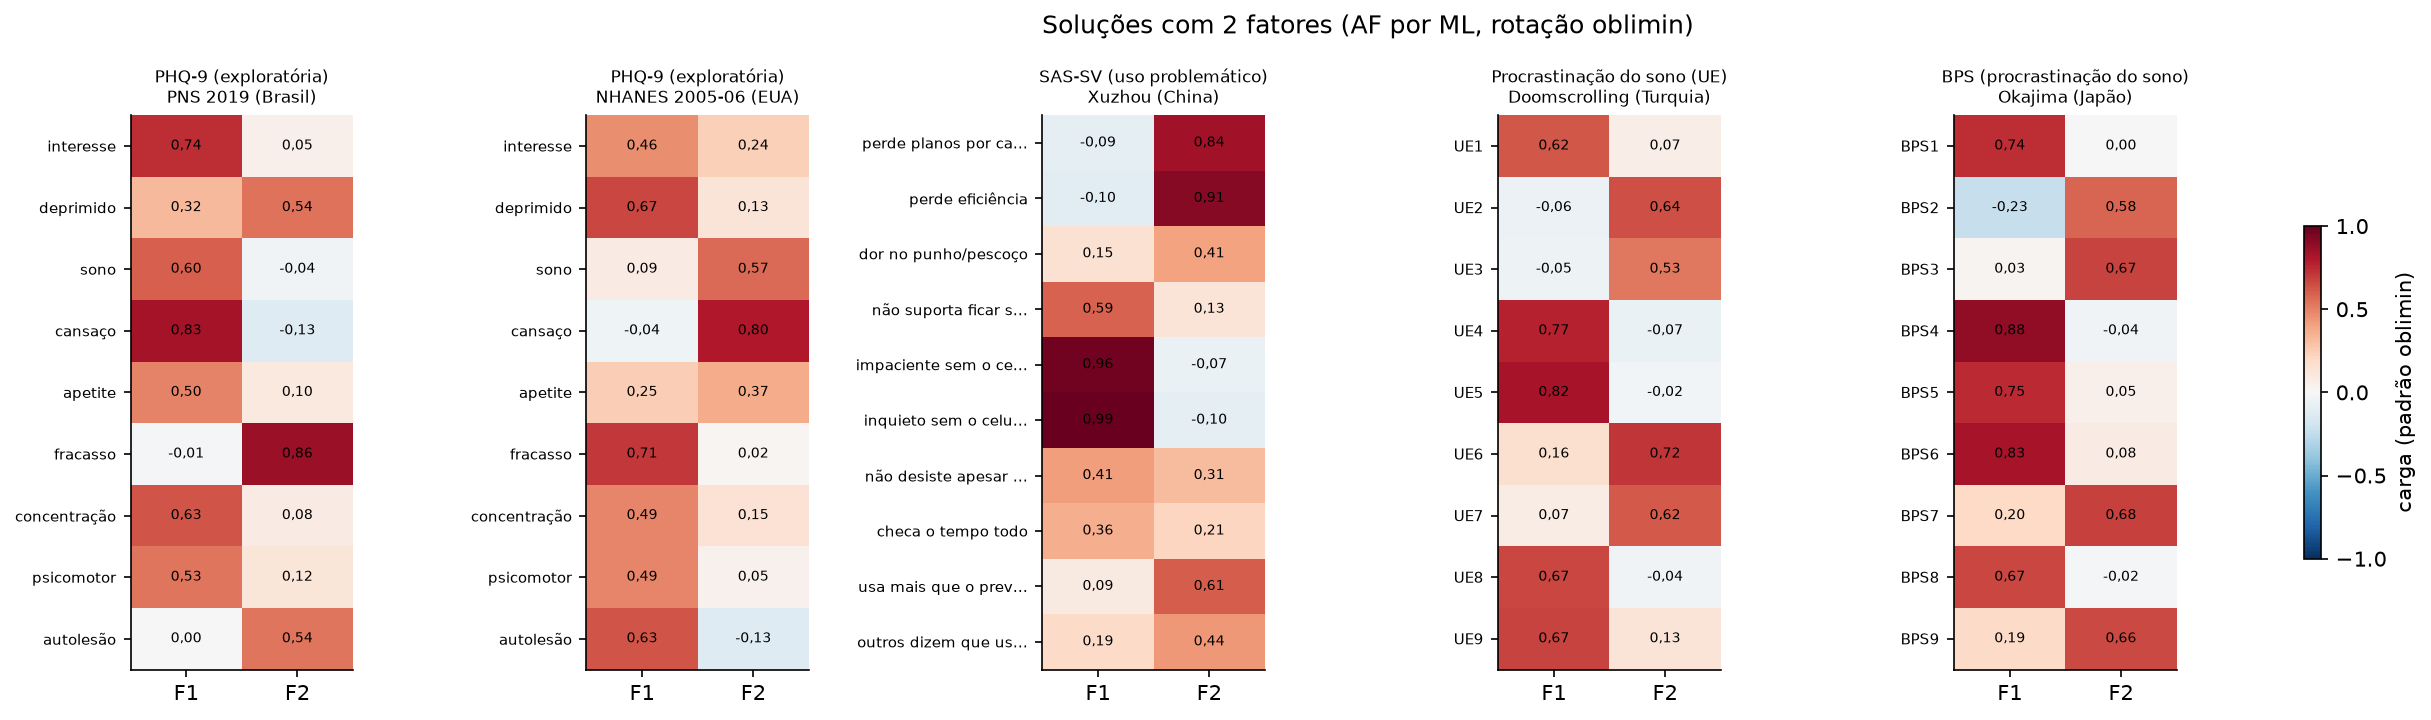

In [7]:
cg = le_csv(TAB / "af_cargas.csv"); phi = le_csv(TAB / "af_phi.csv")
display(phi)
display(Image(filename=str(FIG / "cargas_multifator.png")))

**Leitura.**
- **BPS (Japão)**: o 2º fator reúne exatamente os itens de redação invertida (BPS2R, BPS3R, BPS7R, BPS9R) e se
  correlaciona pouco com o 1º (Φ ≈ 0,19). É o padrão de um **fator de método** (efeito da redação), não
  necessariamente de dois construtos.
- **SAS-SV (Xuzhou)**: um fator de "abstinência" (impaciente/inquieto/não suporta ficar sem o celular) e outro de
  "perturbação da rotina" (perde planos, perde eficiência, usa mais que o previsto), com Φ ≈ 0,61: dimensões
  distintas, mas bem correlacionadas.
- **Procrastinação (Turquia)**: dois blocos de itens (UE2, 3, 6, 7 × os demais), Φ ≈ 0,38. Sem codebook, não dá
  para afirmar se o 2º bloco é de itens invertidos.

## 6. Escores: PCA × AF × soma (H2.6)

Escore fatorial pelo método de regressão (Thurstone): $\hat F = Z\,R^{-1}\Lambda\Phi$.

In [8]:
Z = mv.padroniza(Xu)
f_af = mv.escores_regressao(Z, Ru, mlu["cargas"])[:, 0]
pc = mv.pca_svd(Xu)
pc1 = pc["escores"][:, 0]
print("NHANES PHQ-9: r(PC1, AF) =", round(np.corrcoef(pc1, f_af)[0, 1], 4), " r(PC1, soma) =", round(np.corrcoef(pc1, Xu.sum(axis=1))[0, 1], 4))
le_csv(TAB / "escores_correlacao.csv")

NHANES PHQ-9: r(PC1, AF) = 0.9958  r(PC1, soma) = 0.991


,conjunto,n,r_pc1_af,r_pc1_soma,r_af_soma
0,insonia3_vigitel,27048,0.988,1.000,0.985
1,insonia3_nhanes,5551,0.967,1.000,0.962
2,sono7_nhanes,5520,0.991,0.999,0.985
3,phq9_pns,88531,0.997,0.995,0.990
4,phq9_nhanes,4799,0.996,0.991,0.984
5,sassv_xuzhou,2317,0.953,0.999,0.944
6,doomscrolling_turquia,1216,0.999,0.999,0.997
7,procrastinacao_turquia,1216,0.978,0.992,0.945
8,ais_japao,381,0.995,0.999,0.992
9,bps_japao,381,0.971,0.968,0.891


## 7. Robustez: correlação policórica e correlação ponderada

Os itens são ordinais (0–3 ou 0–4). A correlação de Pearson entre categorias subestima a associação entre os
traços contínuos que estão por trás. A **policórica** (Olsson, 1979, doi:10.1007/BF02296207) estima essa
correlação supondo uma normal bivariada latente cortada em limiares: os limiares vêm das proporções marginais e
$\rho$ maximiza a verossimilhança da tabela cruzada. A **ponderada** usa o peso amostral do inquérito.

In [9]:
Xi = nh[["sintoma_1", "sintoma_2", "sintoma_3"]].dropna().to_numpy(int)
Rp = mv.policorica(Xi)
print("NHANES, 3 sintomas — Pearson:\n", np.corrcoef(Xi, rowvar=False).round(3), "\npolicórica:\n", Rp.round(3))
le_csv(TAB / "robustez.csv")[["conjunto", "correlacao", "lambda1", "var1", "k_kaiser", "tucker_vs_pearson"]]

NHANES, 3 sintomas — Pearson:
 [[1.    0.574 0.451]
 [0.574 1.    0.65 ]
 [0.451 0.65  1.   ]] 
policórica:
 [[1.    0.653 0.531]
 [0.653 1.    0.732]
 [0.531 0.732 1.   ]]


,conjunto,correlacao,lambda1,var1,k_kaiser,tucker_vs_pearson
0,insonia3_vigitel,Pearson,2.261,0.754,1,1.000
1,insonia3_vigitel,policórica,2.382,0.794,1,1.000
2,insonia3_vigitel,ponderada pelo peso amostral,2.234,0.745,1,1.000
3,insonia3_nhanes,Pearson,2.120,0.707,1,1.000
4,insonia3_nhanes,policórica,2.281,0.760,1,1.000
5,insonia3_nhanes,ponderada pelo peso amostral,2.101,0.700,1,1.000
6,sono7_nhanes,Pearson,3.527,0.504,2,1.000
7,sono7_nhanes,policórica,4.014,0.573,1,0.998
8,sono7_nhanes,ponderada pelo peso amostral,3.435,0.491,2,0.999
9,phq9_pns,Pearson,4.349,0.483,1,1.000


A policórica aumenta as correlações e o 1º autovalor, como esperado, mas as cargas mantêm o mesmo padrão
(Tucker com a solução de Pearson ≥ 0,994) e a ponderação pelo peso amostral quase não muda nada (Tucker ≥ 0,998).

## 8. Decisão sobre as hipóteses H2.1–H2.6

In [10]:
le_csv(TAB / 'hipoteses.csv')

,hipotese,conjunto,criterio,valor,decisao
0,H2.1,insonia3_vigitel,"análise paralela retém 1 e cargas ≥ 0,50",retém 1; menor carga 0.708; λ1 = 2.261 (75.4%),critério atendido: 1 dimensão
1,H2.1,insonia3_nhanes,"análise paralela retém 1 e cargas ≥ 0,50",retém 1; menor carga 0.631; λ1 = 2.120 (70.7%),critério atendido: 1 dimensão
2,H2.2,vigitel2024 × nhanes0506,"Tucker φ ≥ 0,95","φ = 0.998 (equivalente (≥ 0,95))",critério atendido: estruturas equivalentes
3,H2.3,pns2019 × nhanes0506,"Tucker φ ≥ 0,95 e mesmo número de fatores","φ = 0.997 (equivalente (≥ 0,95)); fatores reti...",critério atendido: estruturas equivalentes
4,H2.4,phq9_pns × phq9_nhanes,maior carga do item de sono no mesmo fator,solução retida de 1 fator nos dois países: o s...,critério atendido
5,"H2.4 (2 fatores, exploratória)",phq9_pns × phq9_nhanes,maior carga do item de sono no mesmo fator,"PNS: somático (com cansaço), carga 0.597; NHAN...",critério atendido
6,H2.5,sassv_xuzhou,análise paralela retém 1,retém 2 (Kaiser 2); λ1 = 4.784 (47.8%),critério não atendido: 2 dimensões
7,H2.5,doomscrolling_turquia,análise paralela retém 1,retém 1 (Kaiser 1); λ1 = 8.750 (58.3%),critério atendido: unidimensional
8,H2.5,procrastinacao_turquia,análise paralela retém 1,retém 2 (Kaiser 2); λ1 = 3.669 (40.8%),critério não atendido: 2 dimensões
9,H2.5,ais_japao,análise paralela retém 1,retém 1 (Kaiser 1); λ1 = 4.690 (58.6%),critério atendido: unidimensional


## Conclusão

- **H2.1 e H2.2**: os 3 sintomas formam 1 fator no Brasil e nos EUA, com estruturas equivalentes
  (Tucker φ = 0,998).
- **H2.3 e H2.4**: o PHQ-9 tem 1 fator nos dois países, equivalente entre eles; o item de sono acompanha o
  cansaço quando se força a solução de 2 fatores.
- **H2.5**: doomscrolling e AIS são unidimensionais; SAS-SV, procrastinação (Turquia) e BPS têm 2 dimensões —
  no BPS, compatível com efeito dos itens invertidos.
- **H2.6**: escore da PCA e escore fatorial ordenam as pessoas quase igual (r ≥ 0,95 em todos os conjuntos).
- Consequência para as próximas specs: os índices por soma simples (insônia 0–12, PHQ-9 0–27, escores totais
  das escalas) são resumos adequados dos construtos, com a ressalva das escalas bidimensionais.